In [1]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from numpy.linalg import norm
import datetime
import math
import multiprocess as mp
import time
import pickle
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from scipy.signal import find_peaks
import pyarrow.feather as feather
sys.path.insert(0, "cellular_cycle")
from cell_cycle_death_model import model
import matplotlib.pyplot as plt

import tqdm

In [2]:
PARAM = pd.read_csv(Path('model_data/parameters.csv'))  # parameter file to use
INIT_CONCS = pd.read_csv(Path('model_data/initial_concentrations.csv'))  # initial concentrations for simulations

TREATMENT = 'LOW'  # set AKT, ERK, and FAK by setting 'ERL' or 'DMSO'
 
CYCDI_CONC = 0
POINTS = 10  # number to divide each condition into, sets the number of points to divide cell cycle

# number of processes to reserve; set to either 10% or 1, whichever is greater
if round(mp.cpu_count()*0.1,0) < 1:
    RES_PROC = 1
else:
    RES_PROC = round(mp.cpu_count()*0.1,0)

PROCESSES = int(mp.cpu_count() - RES_PROC)  # number of pool processes to run at once
SAVEFILES = True  # save files for lyapunov values and mean IMT values
OVERWRITE = False  # Overwrite existing files
VERBOSE = True
SET_JPARAM = False
PARAM_NUM = 2

integrator_options = {
    "rtol": 1e-12,
    "atol": 1e-12
}

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(), 'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
CURDATE = datetime.datetime.now().strftime('%Y%m%d')

t = np.linspace(0, 1000, 1000001)
t_0 = np.linspace(0, 2000, 2000001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 1

# Importing the parameters:

for key in PARAM.keys():
    try:
        if model.parameters[key].value != PARAM[key][0]:
            model.parameters[key].value = PARAM[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [4]:
if SET_JPARAM:
    with open('fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
        frac_prolif_parameters_pso = pickle.load(f)

    frac_prolif_parameters_pso[('cost', 'custom cost populations')] = frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 0.6 kPa DMSO')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 4 kPa erlotinib')] + frac_prolif_parameters_pso[(
    'cost', 'cost population dynamics 55 kPa erlotinib')]
    pso_sort_pops = frac_prolif_parameters_pso.sort_values(by=[('cost', 'custom cost populations')])
    new_params = pso_sort_pops['model parameters']
    # Importing the parameters:
    for key in new_params.keys():
        try:
            if model.parameters[key].value != new_params[key].iloc[PARAM_NUM]:
                model.parameters[key].value = new_params[key].iloc[PARAM_NUM]
        except:
            print(key)
    model.parameters['omega'].value = 200

In [5]:
for key in INIT_CONCS.keys():
    try:
        model.parameters[key].value = INIT_CONCS[key][0] / model.parameters['omega'].value
    except:
        print(key)

model.parameters['CycDi_0'].value = CYCDI_CONC

if TREATMENT == 'ERL':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.2]*151
    
elif TREATMENT == 'DMSO':
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.6,51))
    tmp = list(np.linspace(0.6,1,51))
    AKTs.extend(tmp[1:])
    tmp = [1]*50
    AKTs.extend(tmp)
    
    ERKs = [1]*151
else:
    FAKs = list(np.linspace(0,0.4,51))
    tmp = list(np.linspace(0.4,0.6,51))
    FAKs.extend(tmp[1:])
    tmp = list(np.linspace(0.6,1,51))
    FAKs.extend(tmp[1:])

    AKTs = list(np.linspace(0,0.3,51))
    tmp = list(np.linspace(0.3,0.6,51))
    AKTs.extend(tmp[1:])
    tmp = [0.6]*50
    AKTs.extend(tmp)
    
    ERKs = [0.1]*151

conds = [(AKT, ERK, FAK) for AKT, ERK, FAK, in zip(AKTs, ERKs, FAKs)]

In [6]:
conds[102]

(0.6, 0.1, 0.616)

In [7]:
def zero_one_test_for_chaos(x, n_c=32, rnd_seed=0):
    """
    Gottwald-Melbourne 0-1 test for chaos (scalar time series).
    Returns K in [0,1]; K~0 periodic/quasi-periodic, K~1 chaotic.
    """
    rng = np.random.default_rng(rnd_seed)
    x = np.asarray(x, dtype=float)
    x = x - np.nanmean(x)
    n = len(x)
    m = np.arange(1, n + 1)
    Ks = []
    for _ in range(n_c):
        c = rng.uniform(0, np.pi)
        # translational variables
        sc = np.cumsum(x * np.cos(c * m))
        ss = np.cumsum(x * np.sin(c * m))
        # mean-square displacement
        M = (sc - np.roll(sc, 1))**2 + (ss - np.roll(ss, 1))**2
        M[0] = 0.0
        # correlation with index -> growth rate proxy
        t = np.arange(n, dtype=float)
        # robust slope via OLS of M vs t (no intercept)
        denom = np.dot(t, t) + 1e-12
        slope = float(np.dot(t, M) / denom)
        # K is correlation coefficient between M and t
        K = np.corrcoef(t, M)[0, 1]
        if np.isnan(K):
            K = 0.0
        Ks.append(K)
    return float(np.median(Ks))

def classify_regime(observable, K_threshold=0.7):
    """
    Return 'limit_cycle' if 0-1 test indicates regular dynamics,
    else 'chaotic'.
    """
    K = zero_one_test_for_chaos(observable)
    return ('chaotic' if K >= K_threshold else 'limit_cycle'), K

def finite_diff_loop(arr, dt):
    """Periodic finite difference for one-period template (shape: (M,d))."""
    # central differences with periodic wrap
    return np.vstack([ (arr[(i+1)%len(arr)] - arr[(i-1)%len(arr)])/(2*dt) for i in range(len(arr)) ])

def transverse_distance_series(x_traj, ref_cycle, ref_dcycle):
    # dense grid of phases
    M = ref_cycle.shape[0]
    rs = []
    for x in x_traj:
        # phase alignment: nearest point on reference cycle
        j = np.argmin(np.linalg.norm(ref_cycle - x, axis=1))
        v = ref_dcycle[j]
        vhat = v / (np.linalg.norm(v) + 1e-12)
        d = x - ref_cycle[j]
        d_perp = d - np.dot(d, vhat) * vhat
        rs.append(np.linalg.norm(d_perp))
    return np.array(rs)

def mle_from_pair(x_ref, x_pert, t, max_frac=0.5):
    """
    Simple finite-time MLE estimate from two trajectories:
    slope of log ||x_pert - x_ref|| over initial segment before saturation.
    """
    x_ref = np.asarray(x_ref)
    x_pert = np.asarray(x_pert)
    t = np.asarray(t, dtype=float)
    d = np.linalg.norm(x_pert - x_ref, axis=1) + 1e-15
    # use only early window until distance reaches max_frac of its max
    thresh = max_frac * np.nanmax(d)
    idx = np.where(d < thresh)[0]
    if idx.size < 5:
        return np.nan
    k = idx[-1]
    m, b = np.polyfit(t[idx[:k]], np.log(d[idx[:k]]), 1)
    return float(m)

In [12]:
# set parameters
AKT = 0.6
ERK = 0.1
FAK = 0.616
model.parameters['AKT'].value = AKT
model.parameters['ERK'].value = ERK
model.parameters['FAK'].value = FAK
verbose=VERBOSE

# integration grids
t_long = np.linspace(0, 2000, 2000001)   # for locating cycle + regime classification
t = np.linspace(0, 1000, 1000001)        # for perturbed pair
dt_long = t_long[1] - t_long[0]
dt = t[1] - t[0]

In [13]:
# ---- Baseline long run (used for: regime, template cycle, windows) ----
sim0 = ScipyOdeSimulator(model, t_long, verbose=False, compiler='python',
                         integrator_options=integrator_options).run()
Y0 = sim0.observables        
# pick a clean observable for classification
obs = np.asarray(Y0['obsCdc20'], dtype=float)

# classify regime
regime, Kstat = classify_regime(obs)
if verbose:
    print(f"regime={regime}, K={Kstat:.3f}")

regime=limit_cycle, K=-0.011


In [14]:
# detect peaks to estimate a period
pk, _ = find_peaks(obs, prominence=0.6, distance=10)
# partition peaks into halves to avoid transients
pk2 = pk[pk > (len(obs)//2)]
if pk2.size >= 3:
    periods = np.diff(t_long[pk2])
    T = float(np.median(periods))
else:
    # fallback: assume ~500 units for period if not enough peaks
    T = 500.0

In [36]:
# carve one period template near the end (reference cycle)
if pk2.size >= 3:
    a, b = pk2[-3], pk2[-2]
else:
    # generic window near end
    b = len(t_long)-1
    a = max(0, b - int(T/dt_long))
ref_slice = slice(a, b)
# use first 19 observables as your distances did
# cols = list(Y0.columns)[:19]
ref_cycle = np.asarray(Y0['Skp2_0', 'p21_0'][a:b])
ref_cycle = np.asarray(Y0[cols].iloc[ref_slice].values, dtype=float)
# resample to fixed M points to get a dense template
M = 2000
if ref_cycle.shape[0] < 10:
    # insufficient data for a template
    regime = 'chaotic'  # force chaotic handling
else:
    idxs = np.linspace(0, ref_cycle.shape[0]-1, M).astype(int)
    ref_cycle = ref_cycle[idxs]
ref_dcycle = finite_diff_loop(ref_cycle, dt_long * (b - a) / max(1, M-1))

IndexError: only integers, slices (`:`), ellipsis (`...`), numpy.newaxis (`None`) and integer or boolean arrays are valid indices

In [54]:
Y0.dtype

dtype([('obsSkp2', '<f8'), ('obsp21', '<f8'), ('obsp21p', '<f8'), ('obscdh1act', '<f8'), ('obscdh1inact', '<f8'), ('obsMyc', '<f8'), ('obsCycD', '<f8'), ('obsCycDp21', '<f8'), ('obspRb', '<f8'), ('obspRbp', '<f8'), ('obsE2F', '<f8'), ('obspRbE2F', '<f8'), ('obsCycE', '<f8'), ('obsCycEp21', '<f8'), ('obsCycA', '<f8'), ('obsCycAp21', '<f8'), ('obsCycB', '<f8'), ('obsCycBp21', '<f8'), ('obsCdc20', '<f8'), ('obsBAX', '<f8'), ('obsBAXmBCL2', '<f8'), ('obsBH3', '<f8'), ('obsBH3BCL2', '<f8'), ('obsBAXm', '<f8'), ('obsBCL2', '<f8'), ('obsCycDi', '<f8'), ('obsCycEi', '<f8'), ('obsCycAi', '<f8'), ('obsCycBi', '<f8'), ('obsE2Fi', '<f8'), ('obsCdc20i', '<f8')])

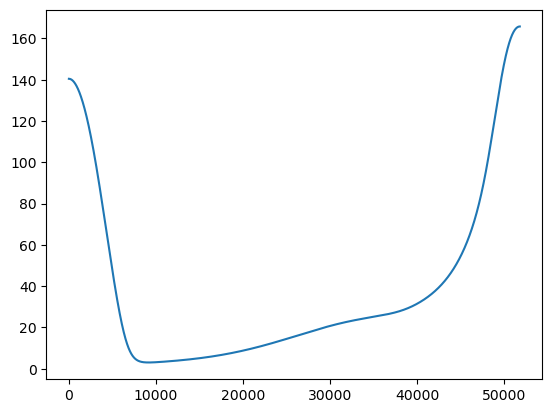

In [23]:
plt.plot(ref_cycle['obsCdc20'])

In [ ]:
# ---------- Now build perturbed pair ----------
# We pick a point inside the same cycle window, split it into 'POINTS' locations (your logic)
all_logz = {}
meanIMT = T

# prepare a short unperturbed run from the chosen initial condition for MLE (chaotic case)
for kk in range(points):
    # initial state near the end-of-transient cycle window
    if pk2.size >= 2:
        window = Y0.iloc[a:b]
        # kk-th position along the window
        tmp_loc = int(round(len(window) / points) * kk)
        tmp_loc = min(tmp_loc, len(window)-1)
        Initial_1 = window.iloc[tmp_loc].values
    else:
        # fallback window (arbitrary slice)
        base = Y0.iloc[-25000:-5000]
        tmp_loc = int(round(len(base) / points) * kk)
        tmp_loc = min(tmp_loc, len(base)-1)
        Initial_1 = base.iloc[tmp_loc].values

    # small perturbation in state space (scale similar to your ep logic)
    ep = 0.001 * 200
    Initial_pert = Initial_1.copy()
    Initial_pert[:19] = Initial_pert[:19] + ep

    # map to model parameters
    prots = ['Skp2_0','p21_0','p21p_0','cdh1act_0','cdh1inact_0','Myc_0','CycD_0','CycDp21_0','pRb_0',
             'pRbp_0','E2F_0','pRbE2F_0','CycE_0','CycEp21_0','CycA_0','CycAp21_0','CycB_0','CycBp21_0','Cdc20_0']
    prot_init = {prots[i]: Initial_pert[i] for i in range(len(prots))}

    for key in prot_init.keys():
        model.parameters[key].value = prot_init[key] / model.parameters['omega'].value

    # simulate perturbed trajectory
    sim1 = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                             integrator_options=integrator_options).run()
    Y1 = sim1.observables
    X1 = np.asarray(Y1[cols].values, dtype=float)  # (N,19)

    # unperturbed companion from the *unperturbed* initial state (for MLE)
    for key in prot_init.keys():
        model.parameters[key].value = Initial_1[prots.index(key)] / model.parameters['omega'].value
    sim_ref = ScipyOdeSimulator(model, t, verbose=False, compiler='python',
                                integrator_options=integrator_options).run()
    Yref = sim_ref.observables
    X0 = np.asarray(Yref[cols].values, dtype=float)

    if regime == 'limit_cycle':
        # transverse (phase-removed) distance to the reference cycle
        # Option: decimate X1 to reduce cost
        step = 2000
        X1_sub = X1[::step]
        r = transverse_distance_series(X1_sub, ref_cycle, ref_dcycle)
        # log-distance series for your downstream pipeline
        logz = np.log(np.maximum(r, 1e-300))
        all_logz[kk + 1] = logz.tolist()
    else:
        # chaotic: estimate MLE from divergence of perturbed vs unperturbed
        mle = mle_from_pair(X0, X1, t)
        # package a short "series" that encodes the scalar estimate once
        all_logz[kk + 1] = [float(mle)]

    if verbose:
        print(f"[{AKT:.3f},{ERK:.3f},{FAK:.3f}] kk={kk} -> regime={regime}")